In [1]:
from plotnine import (
    ggplot, aes, geom_line, annotate, labs,
    theme_minimal, theme, element_text, element_blank, scale_y_continuous,
)
import numpy as np
import pandas as pd

# Plot y = exp(x)

In [2]:
# Fine grid so the curve is smooth
x = np.linspace(-1, 10, 500)
curve = pd.DataFrame({'x': x, 'y': np.exp(x)})

# Two arbitrary points on the curve; the chord between them lies above it (convexity)
a, b = 6, 9.5
ya, yb = np.exp(a), np.exp(b)

# Chord midpoint vs. curve at the midpoint: mean of exp > exp of mean (Jensen)
m = (a + b) / 2
chord_mid, curve_mid = (ya + yb) / 2, np.exp(m)

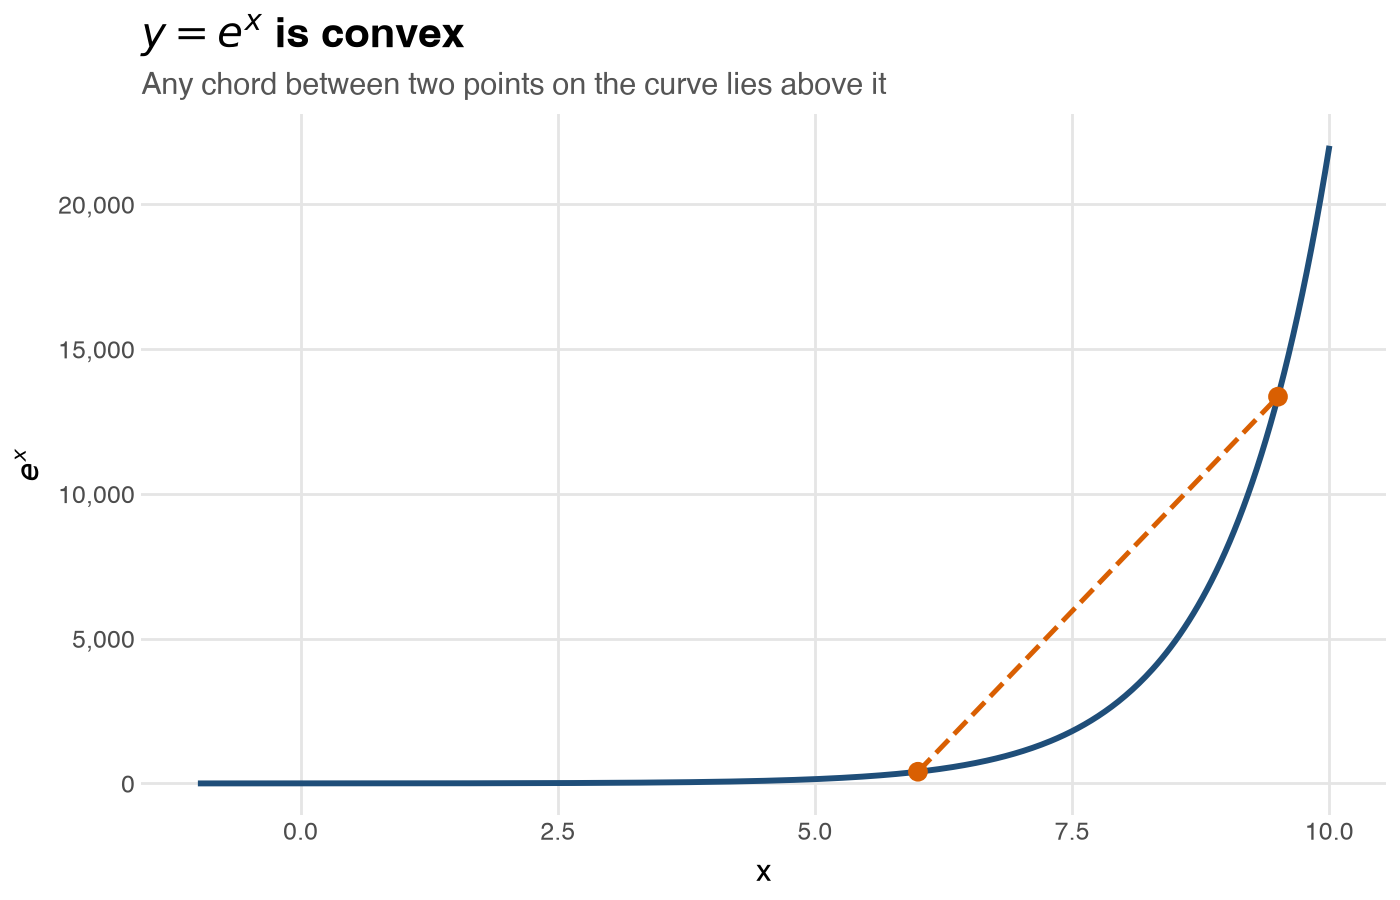

In [3]:
curve_color, chord_color = '#1f4e79', '#d95f02'

(
    ggplot(curve, aes('x', 'y'))
    + geom_line(color=curve_color, size=1.2)
    # Chord between the two points
    + annotate('segment', x=a, xend=b, y=ya, yend=yb,
               color=chord_color, size=1, linetype='dashed')
    + annotate('point', x=[a, b], y=[ya, yb], color=chord_color, size=3)
    # Gap between chord and curve at the midpoint
    # (Uncomment for annotations)
    # + annotate('segment', x=m, xend=m, y=curve_mid, yend=chord_mid,
    #            color='gray', linetype='dotted')
    # + annotate('point', x=[m, m], y=[chord_mid, curve_mid],
    #            color=[chord_color, curve_color], size=2.5)
    # + annotate('text', x=m - 0.25, y=chord_mid, label=r'$\frac{e^a + e^b}{2}$',
    #            ha='right', size=11, color=chord_color)
    # + annotate('text', x=m + 0.25, y=curve_mid, label=r'$e^{(a+b)/2}$',
    #            ha='left', va='top', size=11, color=curve_color)
    + scale_y_continuous(labels=lambda v: [f'{i:,.0f}' for i in v])
    + labs(
        title=r'$y = e^x$ is convex',
        subtitle='Any chord between two points on the curve lies above it',
        x='x', y=r'$e^x$',
    )
    + theme_minimal()
    + theme(
        figure_size=(7, 4.5),
        plot_title=element_text(size=15, weight='bold'),
        plot_subtitle=element_text(size=11, color='#555555'),
        panel_grid_minor=element_blank(),
    )
)